In [1]:
import configparser
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [ ]:
os.chdir('../')

In [2]:
dataset = 'all_noHypoHyper'

In [3]:
data = configparser.ConfigParser(interpolation=configparser.ExtendedInterpolation())
data.read('../data.ini')
data = data['DEFAULT']

## Load

In [4]:
netsig = pd.read_csv("../" + data[f'netsig___{dataset}___out_dir'] + '/all_noHypoHyper_j1_J1_i1000_f0_g01_P3_r0_m1.txt', sep='\t', engine='python', comment='#', header=None)
netsig_RAS = pd.read_csv("../" + data[f'netsig___{dataset}_RAS___out_dir'] + '/all_noHypoHyper_RAS_j1_J1_i1000_f0_g01_P3_r0_m1.txt', sep='\t', engine='python', comment='#', header=None)
netsig_nonRAS = pd.read_csv("../" + data[f'netsig___{dataset}_nonRAS___out_dir'] + '/all_noHypoHyper_nonRAS_j1_J1_i1000_f0_g01_P3_r0_m1.txt', sep='\t', engine='python', comment='#', header=None)

In [5]:
netsig.columns = ['gene', 'score', 'p']
netsig_RAS.columns = ['gene', 'score', 'p']
netsig_nonRAS.columns = ['gene', 'score', 'p']

In [6]:
netsig

,gene,score,p
0,APC,38.8627,0.526474
1,TP53,251.4820,0.267732
2,FBXW7,21.5058,0.555445
3,SMAD4,240.6470,0.008991
4,RNF43,0.0000,1.000000
...,...,...,...
12688,PMCHL2,0.0000,1.000000
12689,RGPD7,10.2383,0.088911
12690,RBMY2FP,0.0000,1.000000
12691,TP53TG1,59.1228,0.041958


In [7]:
netsig.sort_values(by='p', ascending=True)

,gene,score,p
5134,PBK,131.067,0.000999
579,SMURF1,212.154,0.000999
7321,SMURF2,284.909,0.000999
11678,SMAD7,280.987,0.000999
1594,DAXX,231.566,0.000999
...,...,...,...
6618,PIGW,0.000,1.000000
6611,ANKRD13A,0.000,1.000000
6610,ARL6IP4,0.000,1.000000
6633,ESYT1,0.000,1.000000


## p-value analysis

In [8]:
pv_freq = 0.01

In [9]:
numGenes_pvLower = pd.DataFrame(
    [(i, len(netsig.loc[netsig['p'] <= i])) for i in np.clip(np.arange(pv_freq, 1+pv_freq, pv_freq), a_min=0, a_max=1)],
    columns=['p', 'numGenes']
)
numGenes_pvLower_RAS = pd.DataFrame(
    [(i, len(netsig_RAS.loc[netsig_RAS['p'] <= i])) for i in np.clip(np.arange(pv_freq, 1+pv_freq, pv_freq), a_min=0, a_max=1)],
    columns=['p', 'numGenes']
)
numGenes_pvLower_nonRAS = pd.DataFrame(
    [(i, len(netsig_nonRAS.loc[netsig_nonRAS['p'] <= i])) for i in np.clip(np.arange(pv_freq, 1+pv_freq, pv_freq), a_min=0, a_max=1)],
    columns=['p', 'numGenes']
)

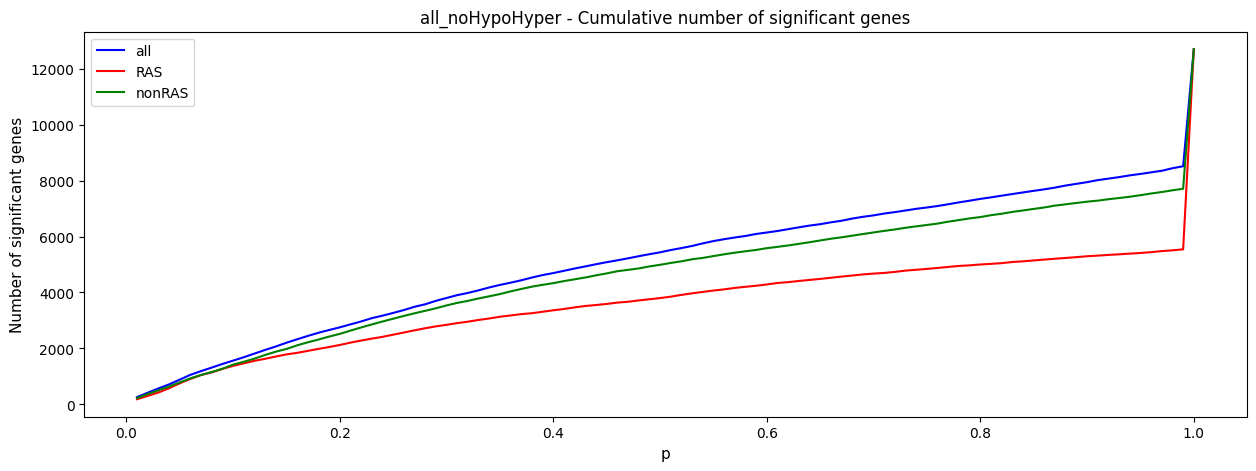

In [10]:
# plot
plt.figure(figsize=(15, 5))
plt.title(dataset + ' - Cumulative number of significant genes')
plt.plot(numGenes_pvLower.set_index('p'), label='all', color='blue')
plt.plot(numGenes_pvLower_RAS.set_index('p'), label='RAS', color='red')
plt.plot(numGenes_pvLower_nonRAS.set_index('p'), label='nonRAS', color='green')
plt.xlabel('p', fontsize=11)
plt.ylabel('Number of significant genes', fontsize=11)
plt.legend(loc='upper left', fontsize=10)
plt.savefig("../" + data[f'plots___{dataset}'] + dataset + '_netsig_cumulativeNumSignificantGenes.png')
plt.show()

In [11]:
numGenes_pvLower.head(10)

,p,numGenes
0,0.01,259
1,0.02,417
2,0.03,569
3,0.04,715
4,0.05,884
5,0.06,1056
6,0.07,1189
7,0.08,1316
8,0.09,1444
9,0.10,1564


In [12]:
genes_all_pv01 = netsig.loc[netsig['p'] < 0.1, 'gene']
genes_all_pv005 = netsig.loc[netsig['p'] < 0.05, 'gene']

genes_RAS_pv01 = netsig_RAS.loc[netsig_RAS['p'] < 0.1, 'gene']
genes_RAS_pv005 = netsig_RAS.loc[netsig_RAS['p'] < 0.05, 'gene']

genes_nonRAS_pv01 = netsig_nonRAS.loc[netsig_nonRAS['p'] < 0.1, 'gene']
genes_nonRAS_pv005 = netsig_nonRAS.loc[netsig_nonRAS['p'] < 0.05, 'gene']

In [13]:
print('all:')
print('Number of significant genes with p-value < 0.1:\t\t\t\t' + str(genes_all_pv01.count()))
print('Number of significant genes with p-value < 0.05:\t\t\t' + str(genes_all_pv005.count()))
print()
print('RAS:')
print('Number of significant genes with p-value < 0.1:\t\t\t\t' + str(genes_RAS_pv01.count()))
print('Number of significant genes with p-value < 0.05:\t\t\t' + str(genes_RAS_pv005.count()))
print()
print('nonRAS:')
print('Number of significant genes with p-value < 0.1:\t\t\t\t' + str(genes_nonRAS_pv01.count()))
print('Number of significant genes with p-value < 0.05:\t\t\t' + str(genes_nonRAS_pv005.count()))

all:
Number of significant genes with p-value < 0.1:				1564
Number of significant genes with p-value < 0.05:			884

RAS:
Number of significant genes with p-value < 0.1:				1376
Number of significant genes with p-value < 0.05:			753

nonRAS:
Number of significant genes with p-value < 0.1:				1422
Number of significant genes with p-value < 0.05:			786


In [14]:
commonGenes_all_RAS_pv005 = set(genes_all_pv005).intersection(set(genes_RAS_pv005))
commonGenes_all_RAS_pv01 = set(genes_all_pv01).intersection(set(genes_RAS_pv01))

commonGenes_all_nonRAS_pv005 = set(genes_all_pv005).intersection(set(genes_nonRAS_pv005))
commonGenes_all_nonRAS_pv01 = set(genes_all_pv01).intersection(set(genes_nonRAS_pv01))

commonGenes_RAS_nonRAS_pv005 = set(genes_RAS_pv005).intersection(set(genes_nonRAS_pv005))
commonGenes_RAS_nonRAS_pv01 = set(genes_RAS_pv01).intersection(set(genes_nonRAS_pv01))

commonGenes_all_RAS_nonRAS_pv005 = set(genes_all_pv005).intersection(set(genes_RAS_pv005)).intersection(set(genes_nonRAS_pv005))
commonGenes_all_RAS_nonRAS_pv01 = set(genes_all_pv01).intersection(set(genes_RAS_pv01)).intersection(set(genes_nonRAS_pv01))

In [15]:
print('all ∩ RAS:')
print('Number of common significant genes with p-value < 0.05:\t' + str(len(commonGenes_all_RAS_pv005)))
print('Number of common significant genes with p-value < 0.1:\t' + str(len(commonGenes_all_RAS_pv01)))
print()
print('all ∩ nonRAS:')
print('Number of common significant genes with p-value < 0.05:\t' + str(len(commonGenes_all_nonRAS_pv005)))
print('Number of common significant genes with p-value < 0.1:\t' + str(len(commonGenes_all_nonRAS_pv01)))
print()
print('RAS ∩ nonRAS:')
print('Number of common significant genes with p-value < 0.05:\t' + str(len(commonGenes_RAS_nonRAS_pv005)))
print('Number of common significant genes with p-value < 0.1:\t' + str(len(commonGenes_RAS_nonRAS_pv01)))
print()
print('all ∩ RAS ∩ nonRAS:')
print('Number of common significant genes with p-value < 0.05:\t' + str(len(commonGenes_all_RAS_nonRAS_pv005)))
print('Number of common significant genes with p-value < 0.1:\t' + str(len(commonGenes_all_RAS_nonRAS_pv01)))

all ∩ RAS:
Number of common significant genes with p-value < 0.05:	507
Number of common significant genes with p-value < 0.1:	972

all ∩ nonRAS:
Number of common significant genes with p-value < 0.05:	607
Number of common significant genes with p-value < 0.1:	1118

RAS ∩ nonRAS:
Number of common significant genes with p-value < 0.05:	422
Number of common significant genes with p-value < 0.1:	789

all ∩ RAS ∩ nonRAS:
Number of common significant genes with p-value < 0.05:	397
Number of common significant genes with p-value < 0.1:	735


In [16]:
genes_RAS_notIn_nonRAS_pv005 = set(genes_RAS_pv005).difference(set(genes_nonRAS_pv005))
genes_RAS_notIn_nonRAS_pv01 = set(genes_RAS_pv01).difference(set(genes_nonRAS_pv01))

genes_nonRAS_notIn_RAS_pv005 = set(genes_nonRAS_pv005).difference(set(genes_RAS_pv005))
genes_nonRAS_notIn_RAS_pv01 = set(genes_nonRAS_pv01).difference(set(genes_RAS_pv01))

nonCommonGenes_RAS_nonRAS_pv005 = genes_RAS_notIn_nonRAS_pv005.union(genes_nonRAS_notIn_RAS_pv005)
nonCommonGenes_RAS_nonRAS_pv01 = genes_RAS_notIn_nonRAS_pv01.union(genes_nonRAS_notIn_RAS_pv01)

In [17]:
print('RAS \\ nonRAS:')
print('Number of significant genes with Significance < 0.05 in RAS-mutated patients but not in non RAS-mutated patients:\t\t' + str(len(genes_RAS_notIn_nonRAS_pv005)))
print('Number of significant genes with Significance < 0.1 in RAS-mutated patients but not in non RAS-mutated patients:\t\t' + str(len(genes_RAS_notIn_nonRAS_pv01)))
print()
print('nonRAS \\ RAS:')
print('Number of significant genes with Significance < 0.05 in non RAS-mutated patients but not in RAS-mutated patients:\t\t' + str(len(genes_nonRAS_notIn_RAS_pv005)))
print('Number of significant genes with Significance < 0.1 in non RAS-mutated patients but not in RAS-mutated patients:\t\t' + str(len(genes_nonRAS_notIn_RAS_pv01)))
print()
print('RAS Δ nonRAS:')
print('Number of significant genes with Significance < 0.05 in RAS-mutated patients or non RAS-mutated patients but not in both:\t' + str(len(nonCommonGenes_RAS_nonRAS_pv005)))
print('Number of significant genes with Significance < 0.1 in RAS-mutated patients or non RAS-mutated patients but not in both:\t' + str(len(nonCommonGenes_RAS_nonRAS_pv01)))

RAS \ nonRAS:
Number of significant genes with Significance < 0.05 in RAS-mutated patients but not in non RAS-mutated patients:		331
Number of significant genes with Significance < 0.1 in RAS-mutated patients but not in non RAS-mutated patients:		587

nonRAS \ RAS:
Number of significant genes with Significance < 0.05 in non RAS-mutated patients but not in RAS-mutated patients:		364
Number of significant genes with Significance < 0.1 in non RAS-mutated patients but not in RAS-mutated patients:		633

RAS Δ nonRAS:
Number of significant genes with Significance < 0.05 in RAS-mutated patients or non RAS-mutated patients but not in both:	695
Number of significant genes with Significance < 0.1 in RAS-mutated patients or non RAS-mutated patients but not in both:	1220


In [18]:
genes_RAS_notIn_nonRAS_pv005

{'A2M',
 'ABP1',
 'ABTB1',
 'ADAP1',
 'ADAR',
 'AGPAT3',
 'ALG1',
 'AMBP',
 'ANKRD28',
 'APBB3',
 'APC2',
 'ARHGAP4',
 'ARHGEF1',
 'ARHGEF18',
 'ARL3',
 'ASCL3',
 'ASCL4',
 'ASPG',
 'ATF7IP',
 'ATOH7',
 'ATOH8',
 'ATP6V0E1',
 'AXIN1',
 'AZGP1',
 'BAAT',
 'BAIAP2',
 'BARX1',
 'BAZ1A',
 'BCAR3',
 'BHLHA9',
 'BLK',
 'BRCA2',
 'BTBD2',
 'BTC',
 'C10orf35',
 'C1QTNF5',
 'C1orf25',
 'C4BPA',
 'C4orf44',
 'C5orf22',
 'C6orf15',
 'CACNG2',
 'CAPN9',
 'CCDC106',
 'CCDC63',
 'CCDC97',
 'CCL25',
 'CCNA2',
 'CCNE2',
 'CD1B',
 'CD40LG',
 'CD59',
 'CD80',
 'CDH11',
 'CDH6',
 'CDH9',
 'CDKN1C',
 'CDKN2C',
 'CELA1',
 'CELF3',
 'CEP250',
 'CEPT1',
 'CES2',
 'CHP2',
 'CHRD',
 'CLK4',
 'COBL',
 'COMMD9',
 'COPS3',
 'COPS7A',
 'COPS8',
 'COQ5',
 'COX17',
 'CPM',
 'CPN2',
 'CRLF2',
 'CSNK1E',
 'CSTB',
 'CTPS2',
 'CUL1',
 'CYP24A1',
 'DAOA',
 'DAZ4',
 'DEGS1',
 'DERL3',
 'DGKQ',
 'DLEU1',
 'DLG5',
 'DLX1',
 'DNAJC2',
 'DOCK8',
 'DUSP12',
 'DYNC1I1',
 'DYRK2',
 'ECSIT',
 'EDIL3',
 'EFEMP2',
 'EGR1',
 'ELOVL4

In [19]:
genes_RAS_notIn_nonRAS_pv01

{'ABP1',
 'ABTB1',
 'ACAP2',
 'ACE2',
 'ACOT7',
 'ACP6',
 'ACPP',
 'ACTR6',
 'ACVR2A',
 'ADAMTS4',
 'ADAP1',
 'ADORA1',
 'ADPGK',
 'AGPAT3',
 'AHDC1',
 'AK5',
 'AKAP5',
 'AKIRIN2',
 'AKNA',
 'AKT1S1',
 'ALCAM',
 'ALG1',
 'ALG5',
 'ALPPL2',
 'AMBP',
 'AMY1B',
 'ANKRD17',
 'ANKRD28',
 'ANKS1B',
 'ANP32B',
 'ANTXR2',
 'APBB1IP',
 'APBB3',
 'APOD',
 'APP',
 'APPL1',
 'ARC',
 'ARF4',
 'ARHGAP4',
 'ARHGEF18',
 'ARHGEF3',
 'ARID3C',
 'ARID4A',
 'ARID5A',
 'ARL15',
 'ARL4D',
 'ARL5A',
 'ASCL3',
 'ASCL4',
 'ASPG',
 'ASPM',
 'ATF7IP',
 'ATOH7',
 'ATOH8',
 'ATP2B4',
 'ATP6V0E1',
 'ATXN10',
 'BAAT',
 'BAIAP2',
 'BAIAP3',
 'BAK1',
 'BAT2L',
 'BAZ1A',
 'BCAR3',
 'BCR',
 'BEND2',
 'BHLHA9',
 'BLK',
 'BMP15',
 'BRAF',
 'BSG',
 'BTBD2',
 'BTC',
 'C10orf35',
 'C11orf30',
 'C11orf58',
 'C17orf81',
 'C1QTNF5',
 'C1orf25',
 'C20orf11',
 'C3orf23',
 'C4orf44',
 'C5orf22',
 'C6orf15',
 'C8orf55',
 'CACNG2',
 'CADM1',
 'CAPN3',
 'CAPN9',
 'CBFA2T3',
 'CCDC63',
 'CCK',
 'CCL18',
 'CCL19',
 'CCL21',
 'CCNA2',
 